# Project 3: Email Spam Detection
**Oasis Infobyte Data Science Internship**

**Goal:** Build a model that reads a message and decides whether it is **spam** (unwanted junk) or **ham** (a normal message).

This is a **text classification** problem. Computers cannot read words, so we convert text into numbers using **TF-IDF**, then train a classifier.

**Steps:** Import libraries, load data, understand data, EDA, text cleaning, TF-IDF, train models, evaluate, test on new messages, conclusion.

## 1. Import Libraries

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset
We use the popular **SMS Spam Collection** dataset (5,572 messages labelled `ham` or `spam`). It is the standard dataset used for this task (the same one found on Kaggle as `spam.csv`).

The code downloads it automatically. If the download fails, it asks you to **upload the Kaggle `spam.csv` file** (the code handles that format too).

In [ ]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

try:
    # This file is tab-separated and has no header row
    df = pd.read_csv(url, sep="\t", header=None, names=["label", "message"])
    print("Dataset downloaded successfully.")
except Exception as e:
    print("Download failed. Please upload spam.csv manually.")
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)), encoding="latin-1")
    # Kaggle version has columns v1 (label) and v2 (message) plus empty columns
    df = df[["v1", "v2"]]
    df.columns = ["label", "message"]

df.head()

Dataset downloaded successfully.


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Understand the Data

In [ ]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate messages:", df.duplicated().sum())

# Remove duplicates so the same message is not in both train and test sets
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

print("\nClass counts:")
print(df["label"].value_counts())

Missing values:
 label      0
message    0
dtype: int64

Duplicate messages: 403
Shape after removing duplicates: (5169, 2)

Class counts:
label
ham     4516
spam     653
Name: count, dtype: int64


In [ ]:
# Convert labels to numbers: ham = 0, spam = 1
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
df.head()

,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 4. Exploratory Data Analysis (EDA)

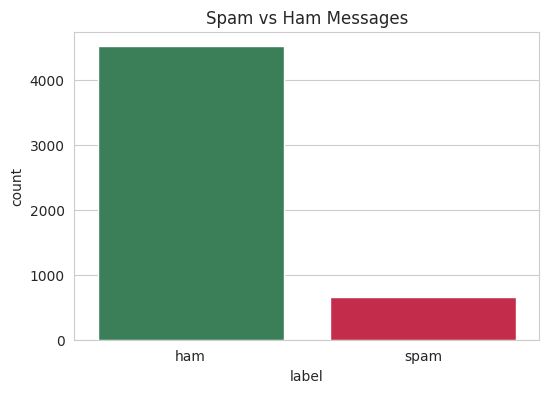

label
ham     87.37
spam    12.63
Name: proportion, dtype: float64


In [ ]:
# 4.1 How many spam vs ham?
plt.figure(figsize=(6, 4))
sns.countplot(x="label", data=df, palette=["seagreen", "crimson"])
plt.title("Spam vs Ham Messages")
plt.show()

print((df["label"].value_counts(normalize=True) * 100).round(2))

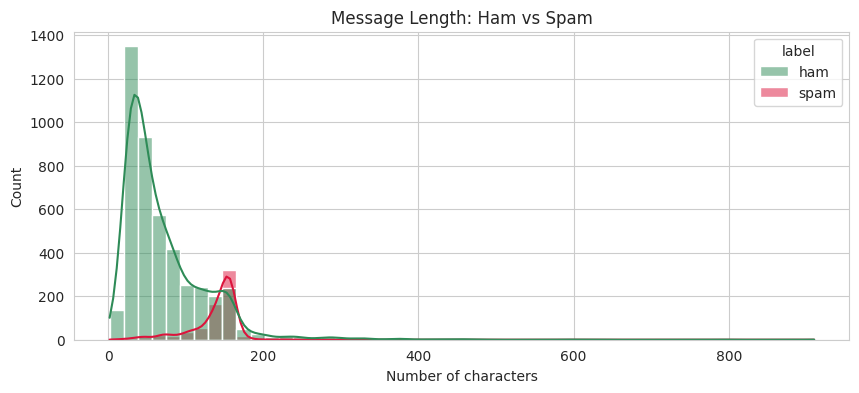

       length  word_count
label                    
ham      70.9        14.2
spam    137.7        23.7


In [ ]:
# 4.2 Message length: spam messages are often longer
df["length"] = df["message"].apply(len)
df["word_count"] = df["message"].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 4))
sns.histplot(data=df, x="length", hue="label", bins=50, kde=True,
             palette={"ham": "seagreen", "spam": "crimson"})
plt.title("Message Length: Ham vs Spam")
plt.xlabel("Number of characters")
plt.show()

print(df.groupby("label")[["length", "word_count"]].mean().round(1))

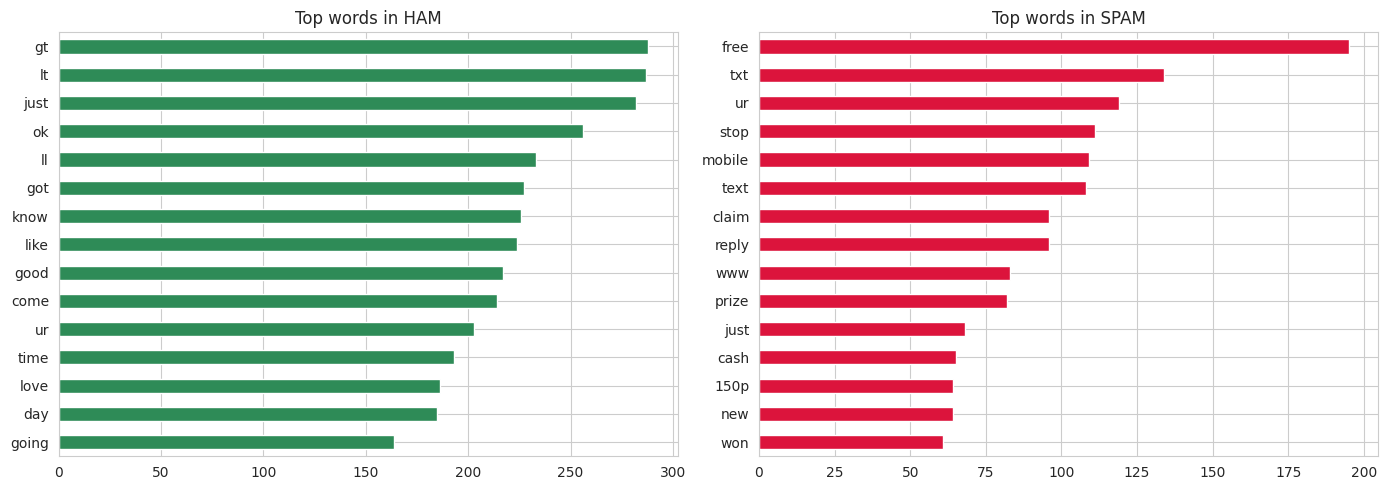

In [ ]:
# 4.3 Most common words in each class (stop words like "the", "is" removed)
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english")
    counts = cv.fit_transform(texts)
    freq = np.asarray(counts.sum(axis=0)).ravel()
    words = cv.get_feature_names_out()
    return pd.Series(freq, index=words).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_words(df[df["label"] == "ham"]["message"]).sort_values().plot(
    kind="barh", ax=axes[0], color="seagreen", title="Top words in HAM")
top_words(df[df["label"] == "spam"]["message"]).sort_values().plot(
    kind="barh", ax=axes[1], color="crimson", title="Top words in SPAM")
plt.tight_layout()
plt.show()

**EDA Observations**
- The data is **imbalanced**: far more ham than spam (roughly 87% / 13%). So accuracy alone can be misleading and we also check precision, recall and F1.
- Spam messages are usually longer.
- Spam commonly uses words like *free*, *call*, *txt*, *claim*, *prize*, *urgent*.

## 5. Text Preprocessing
Steps:
1. **Clean** the text: lowercase, remove numbers/punctuation/extra spaces.
2. **TF-IDF**: turns each message into numbers. Words that are important to a message but rare overall get higher scores. Stop words (the, is, and...) are removed.

In [ ]:
def clean_text(text):
    text = text.lower()                         # lowercase
    text = re.sub(r"http\S+|www\S+", " ", text)  # remove links
    text = re.sub(r"[^a-z\s]", " ", text)        # keep letters only
    text = re.sub(r"\s+", " ", text).strip()     # remove extra spaces
    return text

df["clean_message"] = df["message"].apply(clean_text)
df[["message", "clean_message"]].head()

,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [ ]:
# Split data: 80% train, 20% test. stratify keeps the spam ratio the same in both.
X = df["clean_message"]
y = df["label_num"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training messages:", len(X_train))
print("Testing messages :", len(X_test))

Training messages: 4135
Testing messages : 1034


In [ ]:
# TF-IDF: learn vocabulary from TRAINING data only, then convert both sets
tfidf = TfidfVectorizer(stop_words="english", max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF matrix shape (messages x words):", X_train_tfidf.shape)

TF-IDF matrix shape (messages x words): (4135, 5000)


## 6. Train Models
We train 3 popular text classifiers.

In [ ]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
}

rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),   # of predicted spam, how many were spam
        "Recall": recall_score(y_test, pred),         # of real spam, how many we caught
        "F1 Score": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("F1 Score", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9778,0.9655,0.8550,0.9069
1,Naive Bayes,0.9710,1.0000,0.7710,0.8707
2,Logistic Regression,0.9545,0.9773,0.6565,0.7854


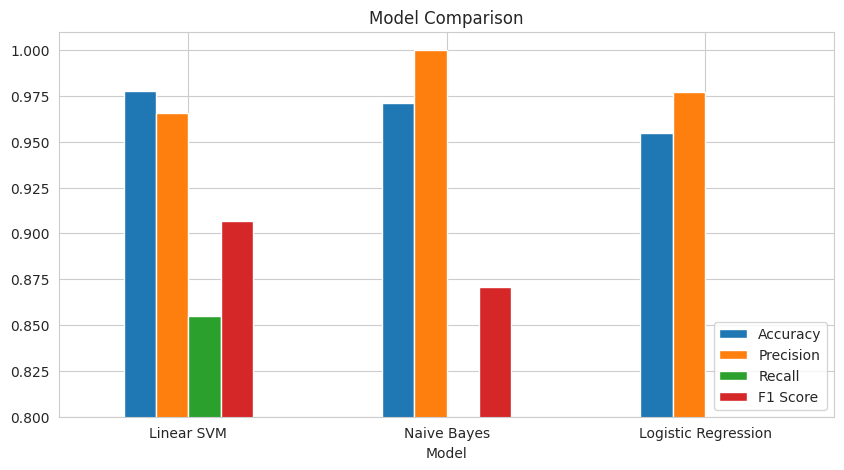

In [ ]:
# Visual comparison
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.8, 1.01))
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 7. Evaluate the Best Model

In [ ]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
best_pred = predictions[best_name]
print("Best model:", best_name)
print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("\nClassification Report:\n")
print(classification_report(y_test, best_pred, target_names=["Ham", "Spam"]))

Best model: Linear SVM
Accuracy: 0.9778

Classification Report:

              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       903
        Spam       0.97      0.85      0.91       131

    accuracy                           0.98      1034
   macro avg       0.97      0.93      0.95      1034
weighted avg       0.98      0.98      0.98      1034



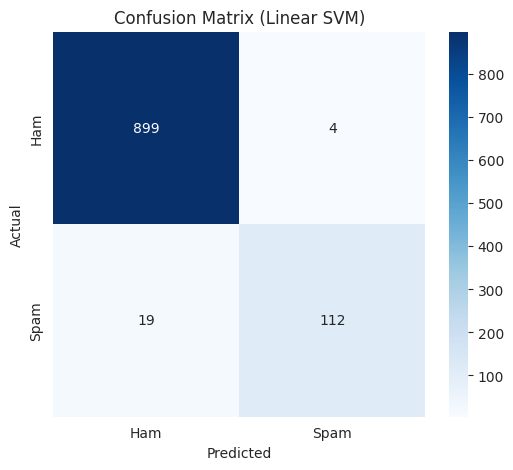

Normal messages correctly kept   : 899
Normal messages wrongly marked spam (false alarms): 4
Spam missed (got into inbox)     : 19
Spam correctly caught            : 112


In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix ({best_name})")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Normal messages correctly kept   : {tn}")
print(f"Normal messages wrongly marked spam (false alarms): {fp}")
print(f"Spam missed (got into inbox)     : {fn}")
print(f"Spam correctly caught            : {tp}")

## 8. Test on New Messages

In [ ]:
def predict_message(text):
    cleaned = clean_text(text)
    vector = tfidf.transform([cleaned])
    result = best_model.predict(vector)[0]
    return "SPAM" if result == 1 else "HAM (not spam)"

test_messages = [
    "Congratulations! You have won a FREE prize. Call now to claim your reward!",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT! Your account has been selected for a cash prize of 1000. Reply WIN now",
    "Please send me the project report by evening. Thanks.",
]

for msg in test_messages:
    print(f"Message : {msg}")
    print(f"Result  : {predict_message(msg)}\n")

Message : Congratulations! You have won a FREE prize. Call now to claim your reward!
Result  : SPAM

Message : Hey, are we still meeting for lunch tomorrow?
Result  : HAM (not spam)

Message : URGENT! Your account has been selected for a cash prize of 1000. Reply WIN now
Result  : SPAM

Message : Please send me the project report by evening. Thanks.
Result  : HAM (not spam)



## 9. Conclusion
- The dataset has about 87% ham and 13% spam, so we used precision, recall and F1-score along with accuracy.
- TF-IDF with a simple classifier works very well for spam detection: accuracy is typically around 97% to 99%.
- Naive Bayes, Logistic Regression and Linear SVM all perform strongly. Naive Bayes is fast and tends to have high precision, while SVM often has the best recall.
- Spam is characterised by words such as *free*, *win*, *call*, *claim*, *urgent* and tends to be longer.
- In spam filters, **precision matters a lot**, because wrongly marking a real message as spam is costly.

**Limitations and improvements:** this dataset is SMS messages (the same method works on emails if you have an email dataset with a label column). You can improve it with `GridSearchCV`, n-grams (`ngram_range=(1,2)`), stemming, or deep learning models.